# Detector YOLO11n — sin aumentos vs. con aumentos (3 clases, YOLO clasifica solo)

**Modelo.** El mismo YOLO11n, pero prediciendo **3 clases** (ascaris, trichuris, uncinaria) en vez de
una sola. Cada caja que encuentra ya trae su especie: es la cabeza de clasificación **del propio YOLO**,
sin un clasificador separado. El profesor de Deep Learning pidió este modelo como comparación directa
contra el pipeline de dos etapas (detector de 1 clase + clasificador aparte, rama ML o DL).

**Pregunta.** (a) ¿Los aumentos cambian el desempeño de detección, igual que en el modelo de 1 clase?
(b) ¿Qué tan bien clasifica la especie esta única cabeza, comparado con los clasificadores de la rama
ML/DL que ven el recorte ya aislado y ampliado?

**Qué se compara.** Los dos modelos se entrenan aquí mismo, en GPU, con la misma semilla (42) y el mismo
split; solo cambian los aumentos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from ultralytics import YOLO

In [2]:
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "CLAUDE.md").is_file())
BASE_WEIGHTS = ROOT / "detector/outputs/weights/yolo11n.pt"
OUTPUT_DIR = ROOT / "dl/outputs/yolo"
EXTERNAL_DIR = ROOT / "data" / "external_fov"  
EXTERNAL_CSV = EXTERNAL_DIR / "external.csv"
VALID_IMAGES_DIR = ROOT / "data" / "raw" / "valid" / "images"
VALID_LABELS_DIR = ROOT / "data" / "raw" / "valid" / "labels"
IMAGE_SUFFIXES = (".jpg", ".jpeg", ".png", ".bmp")

SEED = 42
SINGLE_CLS = False
IMAGE_SIZE = 640
EPOCHS = 100
PATIENCE = 20

RUNS = {
    "No augmentation": {"data": ROOT / "data/raw/data.yaml", "hsv_h": 0, "hsv_s": 0, "hsv_v": 0,
                         "name": "yolo_3class_noaug"},
    "Augmentation": {"data": ROOT / "data/aug/data.yaml", "hsv_h": 0.05, "hsv_s": 0.8, "hsv_v": 0.5,
                      "name": "yolo_3class_aug"},
}
MODEL_COLORS = dict(zip(RUNS, ["#eb6834", "#2a78d6"]))
INK, NOT_COUNTED = "#0b0b0b", "#e6e5e1"

PHOTOS_USED_TO_DESIGN_AUGMENTATIONS = {"a-image2.png"}
CONF_THRESHOLD = 0.25
CONF_CURVE = [round(conf, 2) for conf in np.arange(0.05, 0.96, 0.05)]
CONF_LOWEST = 0.001
MAX_BOXES_PER_PHOTO = 50
DEVICE = 0 if torch.cuda.is_available() else "cpu"
TRAINING = False
MATCH_IOU = 0.5

print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
assert BASE_WEIGHTS.is_file(), f"missing base weights: {BASE_WEIGHTS}"
assert EXTERNAL_DIR.is_dir(), f"missing {EXTERNAL_DIR}"
print("external photos:", EXTERNAL_DIR)


device: NVIDIA H100 NVL
external photos: /home/scar-test/deep-learning/data/external_fov


## 1. Artefactos de entrenamiento

In [3]:
for label, cfg in RUNS.items():
    run_dir = OUTPUT_DIR / cfg["name"]
    weights = run_dir / "weights" / "best.pt"
    metrics = run_dir / "results.csv"
    assert weights.is_file(), f"missing saved weights: {weights}"
    assert metrics.is_file(), f"missing saved metrics: {metrics}"
    print(f"{label}: artefactos encontrados en {run_dir}; no se entrena")

MODELS = {label: OUTPUT_DIR / cfg["name"] / "weights" / "best.pt" for label, cfg in RUNS.items()}
assert all(path.is_file() for path in MODELS.values()), "missing weights after training"
MODELS

No augmentation: artefactos encontrados en /home/scar-test/deep-learning/dl/outputs/yolo/yolo_3class_noaug; no se entrena
Augmentation: artefactos encontrados en /home/scar-test/deep-learning/dl/outputs/yolo/yolo_3class_aug; no se entrena


{'No augmentation': PosixPath('/home/scar-test/deep-learning/dl/outputs/yolo/yolo_3class_noaug/weights/best.pt'),
 'Augmentation': PosixPath('/home/scar-test/deep-learning/dl/outputs/yolo/yolo_3class_aug/weights/best.pt')}

## 2. Curvas de entrenamiento y tiempo

De `results.csv` de cada corrida: las pérdidas (caja, clase, DFL) y las métricas (precisión, recall,
mAP50, mAP50-95) en cada época, train y valid, un color por modelo. El tiempo total sale de la última
fila de `results.csv` (columna `time`, en segundos).

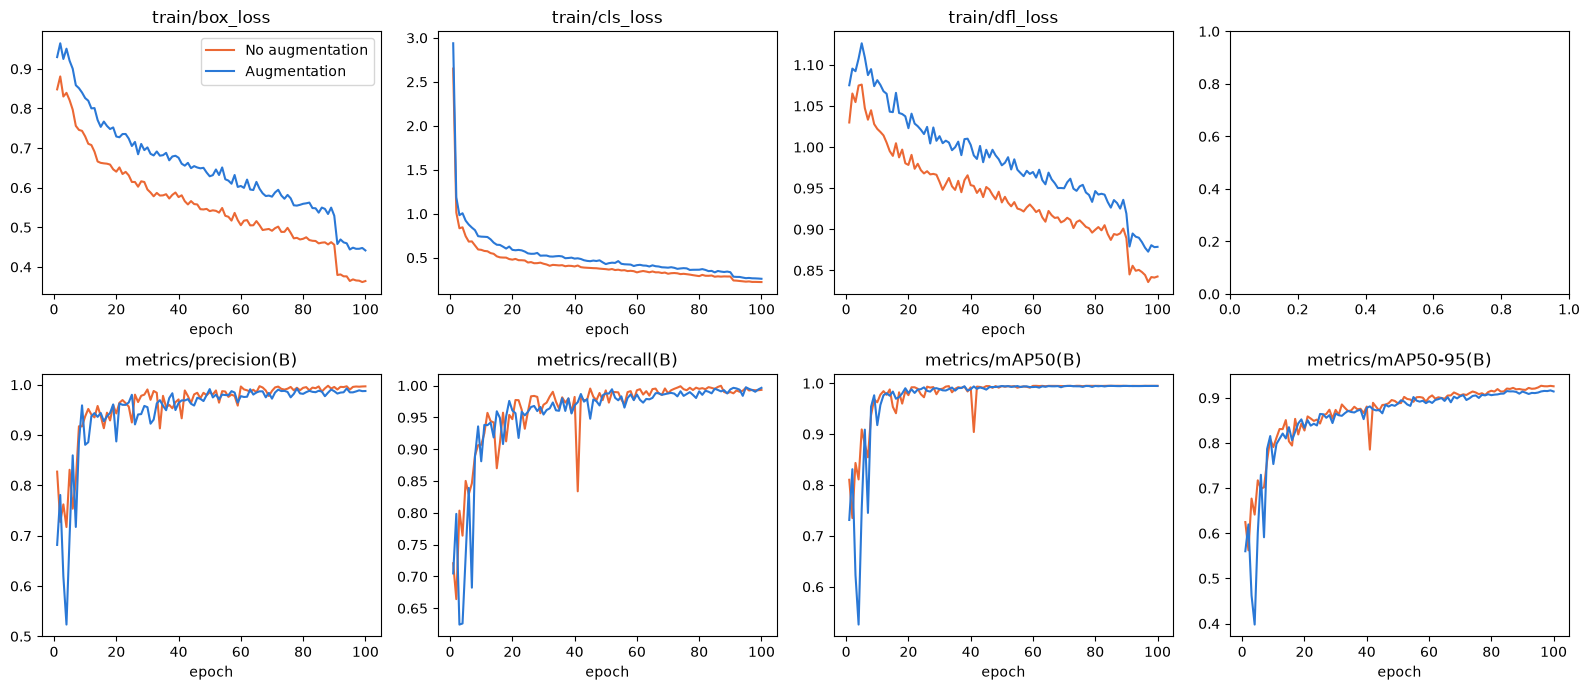

No augmentation    386.3
Augmentation       387.2
Name: minutes on GPU, dtype: float64

In [4]:
results = {label: pd.read_csv(OUTPUT_DIR / cfg["name"] / "results.csv").rename(columns=str.strip)
           for label, cfg in RUNS.items()}

loss_cols = ["train/box_loss", "train/cls_loss", "train/dfl_loss"]
metric_cols = ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]

fig, axes = plt.subplots(2, max(len(loss_cols), len(metric_cols)), figsize=(16, 7))
for label, df in results.items():
    color = MODEL_COLORS[label]
    for ax, col in zip(axes[0], loss_cols):
        ax.plot(df.epoch, df[col], color=color, label=label)
        ax.set(title=col, xlabel="epoch")
    for ax, col in zip(axes[1], metric_cols):
        ax.plot(df.epoch, df[col], color=color, label=label)
        ax.set(title=col, xlabel="epoch")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

time_minutes = {label: df["time"].iloc[-1] / 60 for label, df in results.items()}
pd.Series(time_minutes, name="minutes on GPU").round(1)

**Curvas de entrenamiento del detector de 3 clases (naranja: sin aumentos; azul: con aumentos).** Las pérdidas de entrenamiento bajan de forma continua; la corrida con aumentos queda por encima (`box_loss` final de 0,44 frente a 0,36) porque sus imágenes son más difíciles. En la época 91 ambas pérdidas caen de golpe, porque Ultralytics apaga el mosaico en las últimas 10 épocas (`close_mosaic: 10`). En validación, precisión, recall y mAP50 llegan a ~0,99 desde la época ~20 y el mAP50 (0,995 en ambas) está saturado. Hay inestabilidad en las primeras épocas, sobre todo con aumentos, y una caída puntual sin aumentos en la época 41 de la que se recupera enseguida. Las dos corridas difieren de forma pequeña pero consistente en mAP50-95: 0,9257 sin aumentos frente a 0,9142 con aumentos en la época 100, y 0,9234 frente a 0,9129 en el promedio de las últimas 10 épocas. Frente al detector de 1 clase (0,9267 y 0,9224), añadir la clasificación de especie no empeora la localización en `valid`. Como `valid` es de la misma fuente que `train` y el EDA mostró que el fondo predice la especie, estas curvas no garantizan el mismo desempeño en fotos externas. Cada entrenamiento duró ~6,4 horas en CPU (~232 s por época).


## 3. Arquitectura

YOLO11n tiene una sola red para las dos corridas (sin/con aumentos): lo único que cambia entre ellas es
la receta de entrenamiento, no la arquitectura. Se describe una sola vez.

**Las tres partes.**

- **Backbone (columna vertebral).** Convoluciones que reducen la imagen (640×640 → mapas más chicos, más
  canales) y extraen rasgos: bordes, texturas, formas. Usa bloques **C3k2** (una versión más liviana de
  los bloques C2f de YOLOv8: divide los canales, pasa una parte por convoluciones pequeñas y la junta con
  la otra) y, antes del final, un bloque **C2PSA** (atención a una parte de los canales, nuevo en YOLO11)
  que ayuda a la red a enfocarse en la zona del huevo y no en el fondo del campo del microscopio. Al final
  del backbone hay un **SPPF** (Spatial Pyramid Pooling - Fast): aplica max-pooling a varias escalas y las
  junta, para que la red vea el huevo entero sin importar su tamaño en la foto.
- **Neck (cuello).** Combina los mapas de distintas resoluciones del backbone (tipo PAN/FPN): sube la
  información de los mapas chicos (más contexto, menos detalle) y la mezcla con los mapas grandes (más
  detalle, menos contexto). Así la misma red detecta huevos chicos y grandes en la foto.
- **Head (cabeza), anchor-free.** Por cada celda del mapa final predice: (1) la caja, como una
  distribución de distancias a los 4 bordes en vez de un número fijo (**DFL**, Distribution Focal Loss) y
  (2) la clase (3 clases), con una probabilidad por clase. No usa cajas ancla
  predefinidas (a diferencia de YOLOv3-v5): cada celda decide directamente dónde está el borde.
- **Pérdida.** Caja: **CIoU** (penaliza no solo el solapamiento sino la distancia entre centros y la
  forma) + DFL. Clase: entropía cruzada binaria (BCE) por clase.

**La diferencia con el modelo de 1 clase es solo la última capa de la cabeza**: en vez de predecir 1
probabilidad por celda, predice 3 (una por especie). El resto de la red (backbone, neck, el resto de la
cabeza) es idéntico. Por eso no hay "dos arquitecturas distintas que explicar": es la misma red haciendo
localización y clasificación en la misma pasada, que es justamente el punto de comparación contra el
pipeline de dos etapas.

**Parámetros y capas reales.** `model.info(detailed=True)` imprime cada capa (tipo, parámetros,
dimensiones) y el resumen total (capas, parámetros entrenables, GFLOPs) de la red que se acaba de
entrenar — no un número de memoria, sino el de esta corrida.

In [5]:
model_for_info = YOLO(str(MODELS["No augmentation"]))
layer_summary = model_for_info.info(detailed=True)
layer_summary

layer                                    name                type  gradient  parameters               shape        mu     sigma


    0                     model.0.conv.weight              Conv2d     False         432       [16, 3, 3, 3]  -0.00194     0.147        float32


    1                       model.0.bn.weight         BatchNorm2d     False          16                [16]      3.02      1.93        float32


    1                         model.0.bn.bias         BatchNorm2d     False          16                [16]      0.73      4.29        float32


    2                             model.0.act                SiLU     False           0                  []         -         -              -


    3                     model.1.conv.weight              Conv2d     False        4608      [32, 16, 3, 3]   0.00151    0.0721        float32


... (262 outputs left out)

  180                   model.23.cv3.2.2.bias              Conv2d     False           3                 [3]     -5.53    0.0222        float32


  181                model.23.dfl.conv.weight              Conv2d     False          16       [1, 16, 1, 1]       7.5      4.76        float32


YOLO11n summary: 182 layers, 2,605,369 parameters, 0 gradients, 6.6 GFLOPs


(182, 2605369, 0, 6.5698304)

**Diagrama de bloques.** Versión simplificada de lo descrito arriba, con el tamaño del mapa en cada
etapa (para una entrada de 640×640).

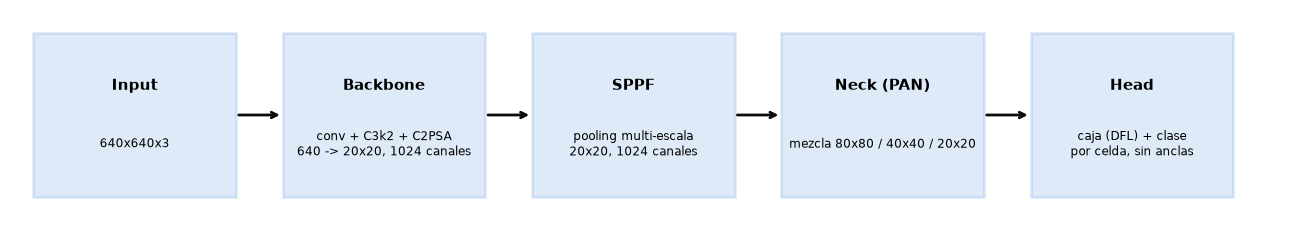

In [6]:
def draw_pipeline(ax, boxes):
    """boxes: list of (label, detail) drawn left to right with arrows between them."""
    width, gap = 2.6, 0.6
    for i, (label, detail) in enumerate(boxes):
        x = i * (width + gap)
        ax.add_patch(Rectangle((x, 0), width, 1.4, facecolor="#2a78d6", alpha=0.15, edgecolor="#2a78d6", linewidth=2))
        ax.text(x + width / 2, 0.95, label, ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(x + width / 2, 0.45, detail, ha="center", va="center", fontsize=8.5)
        if i > 0:
            ax.annotate("", xy=(x, 0.7), xytext=(x - gap, 0.7),
                        arrowprops=dict(arrowstyle="->", linewidth=2, color="#0b0b0b"))
    ax.set_xlim(-0.3, len(boxes) * (width + gap))
    ax.set_ylim(-0.2, 1.6)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(13, 2.4))
draw_pipeline(ax, [
    ("Input", "640x640x3"),
    ("Backbone", "conv + C3k2 + C2PSA\n640 -> 20x20, 1024 canales"),
    ("SPPF", "pooling multi-escala\n20x20, 1024 canales"),
    ("Neck (PAN)", "mezcla 80x80 / 40x40 / 20x20"),
    ("Head", "caja (DFL) + clase\npor celda, sin anclas"),
])
plt.tight_layout()
plt.show()

## 4. Métricas en `valid`

`model.val()` corre sobre el split de validación (nunca `test`) y da las métricas estándar de detección.
Ultralytics guarda además, dentro de la carpeta de cada corrida, las curvas de precisión/recall/F1 contra
el umbral de confianza y la matriz de confusión se muestran tal cual las genera la librería, sin
recalcularlas a mano.

In [7]:
val_metrics = {}
for label, weights in MODELS.items():
    metrics = YOLO(str(weights)).val(data=str(RUNS[label]["data"]), split="val", device=DEVICE, plots=True,
                                      project=str(OUTPUT_DIR), name=RUNS[label]["name"], exist_ok=True)
    val_metrics[label] = {
        "mAP50": metrics.box.map50, "mAP50-95": metrics.box.map,
        "precision": metrics.box.mp, "recall": metrics.box.mr,
    }
val_table = pd.DataFrame(val_metrics).T
val_table["F1"] = 2 * val_table.precision * val_table.recall / (val_table.precision + val_table.recall)
val_table.round(3)

Ultralytics 8.4.195 🚀 Python-3.12.16 torch-2.13.0+cu129 CUDA:0 (NVIDIA H100 NVL, 95320MiB)


YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 286.3±146.8 MB/s, size: 40.2 KB)


val: Scanning /home/scar-test/deep-learning/data/raw/valid/labels.cache... 410 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 410/410 95.5Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 3% ──────────── 1/26 1.3s/it 0.4s<32.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 11% ━─────────── 3/26 2.1it/s 0.8s<11.1s

... (29 outputs left out)

             trichuris        137        137          1      0.989      0.995      0.925


Speed: 0.5ms preprocess, 1.0ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to /home/scar-test/deep-learning/dl/outputs/yolo/yolo_3class_aug


,mAP50,mAP50-95,precision,recall,F1
No augmentation,0.995,0.927,0.996,0.992,0.994
Augmentation,0.995,0.917,0.987,0.994,0.991


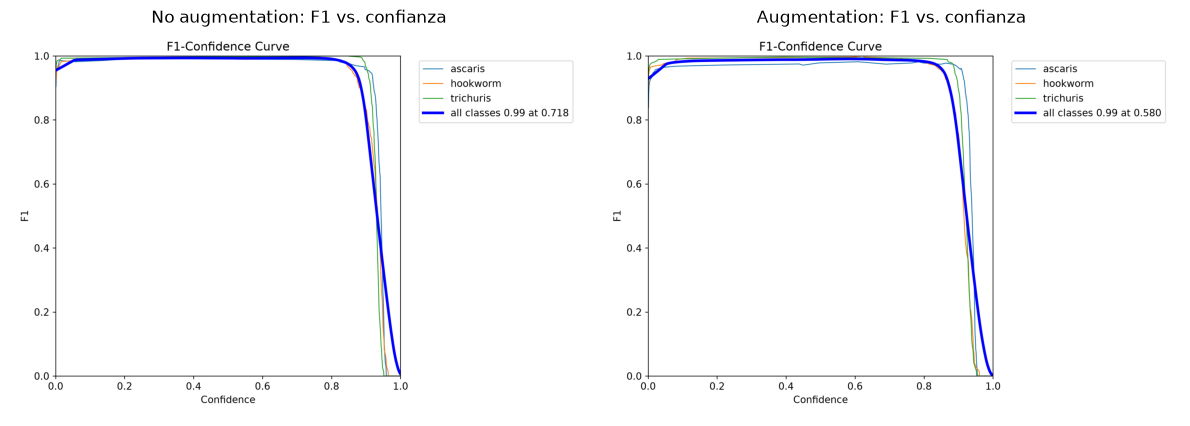

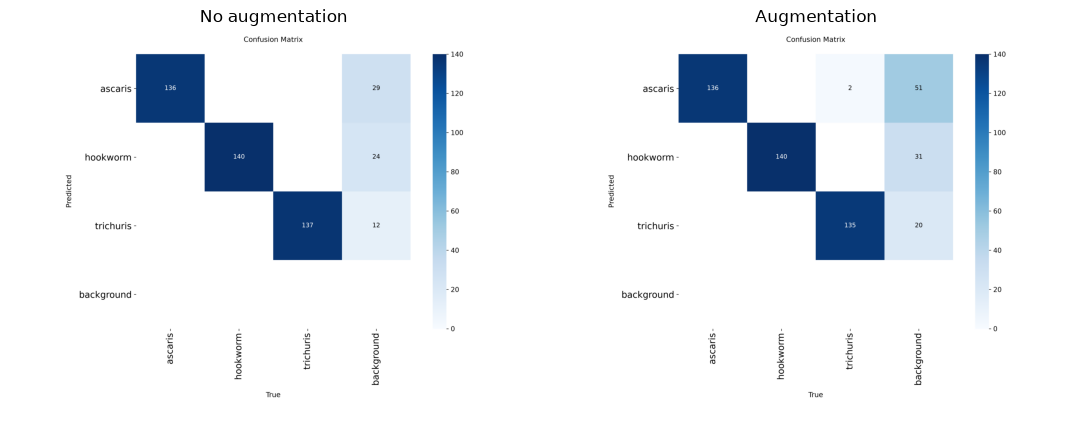

In [8]:
def find_plot(run_dir, *names):
    """Ultralytics names the curves F1_curve.png or BoxF1_curve.png depending on its version."""
    for name in names:
        if (run_dir / name).is_file():
            return run_dir / name
    raise FileNotFoundError(f"none of {names} in {run_dir}")


fig, axes = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 5))
for ax, (label, cfg) in zip(axes, RUNS.items()):
    curve_path = find_plot(OUTPUT_DIR / cfg["name"], "BoxF1_curve.png", "F1_curve.png")
    ax.imshow(Image.open(curve_path))
    ax.set_title(f"{label}: F1 vs. confianza")
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 5))
for ax, (label, cfg) in zip(axes, RUNS.items()):
    confusion_path = find_plot(OUTPUT_DIR / cfg["name"], "confusion_matrix.png")
    ax.imshow(Image.open(confusion_path))
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Curvas F1 frente a confianza y matrices de confusión del detector de 3 clases (`valid`, 413 huevos; filas = predicho, columnas = real).** El F1 se mantiene en ~0,99 en una meseta amplia de umbrales y su máximo para todas las clases es 0,99, con confianza 0,718 sin aumentos y 0,580 con aumentos. Sin aumentos, la matriz muestra los 413 huevos con la especie correcta (136 ascaris, 140 hookworm y 137 trichuris); con aumentos, 411 de 413, con 2 trichuris clasificados como ascaris. Ninguna corrida pierde un huevo. Las cajas sin huevo son 65 sin aumentos y 102 con aumentos; estas cifras son altas porque la matriz se calcula con un umbral de confianza de 0,001 y a 0,25 casi desaparecen. En `valid`, el detector de 3 clases y la CNN final (3 errores de 413 con la semilla 42) quedan a la par. Como este detector ve la foto completa y el EDA mostró que el fondo predice la especie, su acierto en `valid` puede ser optimista; la prueba que decide es la de las fotos externas.


## 5. Fotos externas

Igual que en `detector/notebooks/compare_detectors.ipynb`: cada modelo se corre una vez sobre cada foto
externa, guardando todas las cajas con su puntaje; el umbral se aplica después, sin reinferir.

In [9]:
external_photos = pd.read_csv(EXTERNAL_CSV)
photos_on_disk = {p.name for p in EXTERNAL_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES}
assert photos_on_disk == set(external_photos.image), "fix external.csv first"
external_photos["n_items"] = external_photos.n_items.astype(int)
test_photos = external_photos[external_photos.uso == "prueba"]
print(f"{len(test_photos)} test photos with {test_photos.n_items.sum()} eggs")

98 test photos with 101 eggs


In [10]:
def detect_all(weights_path, image_paths):
    model = YOLO(str(weights_path))
    results = model.predict(source=[str(p) for p in image_paths], imgsz=IMAGE_SIZE, conf=CONF_LOWEST,
                             max_det=MAX_BOXES_PER_PHOTO, device=DEVICE, stream=True, verbose=False)
    rows = []
    for result in results:
        for (x1, y1, x2, y2), score, cls in zip(result.boxes.xyxy.tolist(), result.boxes.conf.tolist(),
                                                 result.boxes.cls.tolist()):
            rows.append({"image": Path(result.path).name, "score": score, "species": result.names[int(cls)],
                         "x1": x1, "y1": y1, "x2": x2, "y2": y2})
    return pd.DataFrame(rows, columns=["image", "score", "species", "x1", "y1", "x2", "y2"])


external_paths = [EXTERNAL_DIR / name for name in external_photos.image]
external_boxes = pd.concat(
    [detect_all(weights, external_paths).assign(model=label) for label, weights in MODELS.items()],
    ignore_index=True,
)
external_boxes.groupby("model").size().rename("boxes found (any score)")

model
Augmentation       170
No augmentation    142
Name: boxes found (any score), dtype: int64

In [11]:
def count_boxes(boxes, conf):
    every_pair = pd.MultiIndex.from_product([list(MODELS), test_photos.image], names=["model", "image"])
    kept = boxes[boxes.score >= conf]
    return kept.groupby(["model", "image"]).size().reindex(every_pair, fill_value=0)


def egg_counts(boxes, conf):
    real_eggs = test_photos.set_index("image").n_items
    box_counts = count_boxes(boxes, conf).unstack("model")
    counts = {}
    for label in MODELS:
        n_boxes = box_counts[label]
        found = np.minimum(n_boxes, real_eggs)
        counts[label] = {"real_eggs": int(real_eggs.sum()), "found": int(found.sum()),
                         "missed": int((real_eggs - found).sum()), "false_alarms": int((n_boxes - found).sum())}
    return pd.DataFrame.from_dict(counts, orient="index").rename_axis("model")


external_counts = egg_counts(external_boxes, CONF_THRESHOLD)
external_counts

,real_eggs,found,missed,false_alarms
model,,,,
No augmentation,101,78,23,4
Augmentation,101,95,6,13


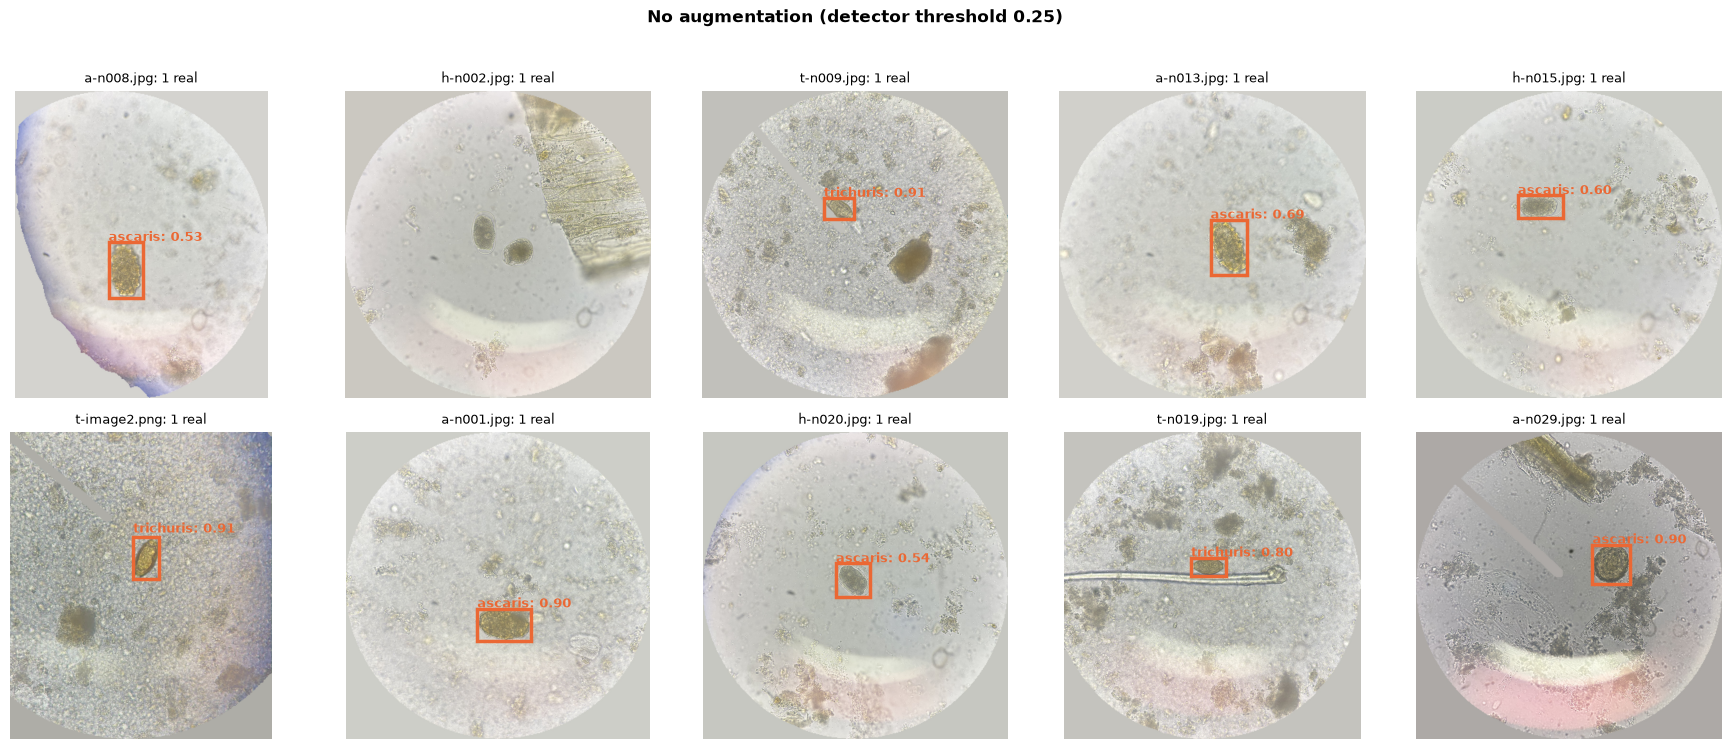

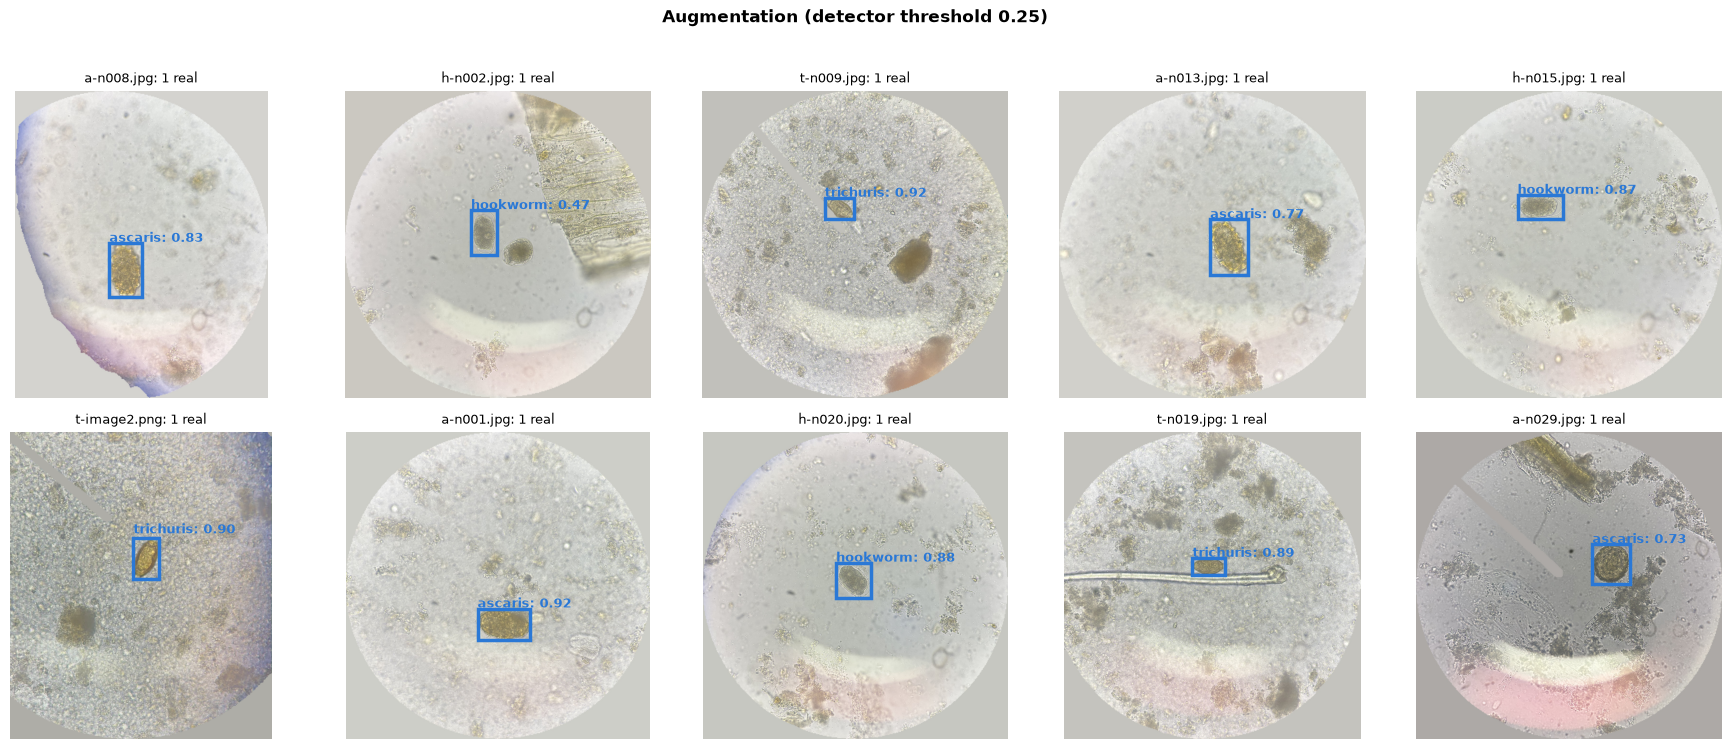

In [12]:
def draw_detections(ax, image_name, model_boxes, color):
    ax.imshow(ImageOps.exif_transpose(Image.open(EXTERNAL_DIR / image_name)))  # upright: iPhone JPGs carry EXIF rotation, and YOLO boxes are in the rotated frame
    shown = model_boxes[(model_boxes.image == image_name) & (model_boxes.score >= CONF_THRESHOLD)]
    for box in shown.itertuples():
        ax.add_patch(Rectangle((box.x1, box.y1), box.x2 - box.x1, box.y2 - box.y1,
                               fill=False, edgecolor=color, linewidth=2.5))
        label = f"{box.score:.2f}" if SINGLE_CLS else f"{box.species}: {box.score:.2f}"
        ax.text(box.x1, box.y1 - 10, label, color=color, fontsize=9, fontweight="bold")
    ax.axis("off")

N_SHOW, N_COLS = 10, 5
rng = np.random.default_rng(SEED)
pool = test_photos.copy()
pool["group"] = pool.species.fillna("control") if "species" in pool.columns else "all"
groups = {g: list(rng.permutation(df.image.values)) for g, df in pool.groupby("group")}
chosen = []
while len(chosen) < N_SHOW and any(groups.values()):
    for g in groups:
        if groups[g] and len(chosen) < N_SHOW:
            chosen.append(groups[g].pop())
sample = external_photos.set_index("image").loc[chosen].reset_index()

n_rows = int(np.ceil(len(sample) / N_COLS))
for label in MODELS:
    model_boxes = external_boxes[external_boxes.model == label]
    fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.6 * N_COLS, 3.8 * n_rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, photo in zip(axes.ravel(), sample.itertuples()):
        draw_detections(ax, photo.image, model_boxes, MODEL_COLORS[label])
        ax.set_title(f"{photo.image}: {photo.n_items} real", fontsize=9)
    fig.suptitle(f"{label} (detector threshold {CONF_THRESHOLD})", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


**Detecciones del YOLO de 3 clases en fotos externas (98 fotos de prueba recortadas al ocular, 101 huevos; umbral 0,25).** Con aumentos encuentra 95 de los 101 huevos (6 perdidos, 13 cajas de más); sin aumentos, solo 78 (23 perdidos). La especie la decide el mismo YOLO: en `comparison.ipynb`, con aumentos, acierta 85 de los 95 huevos que encuentra (89,5 %), y las uncinarias son su punto débil (24 de 33). El sistema de dos etapas (YOLO de 1 clase + EfficientNet-B0) encuentra 100 y acierta 98, así que separar detección y clasificación funciona mejor fuera de Chula. Como este modelo ve la foto completa y el EDA mostró que el fondo predice la especie, su acierto no demuestra que se base en la forma del huevo.